In [43]:
# required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [44]:
#load the dataset
df = pd.read_csv('decision_tree_dataset.csv')
df

,age,income,credit_score,city,gender,purchases,loan_amount,approved
0,41,16832.970365,646.435852,Hyderabad,Female,2,NaN,0
1,61,24958.920783,772.103370,Bangalore,Female,2,109037.369348,0
2,29,26661.565307,742.165011,Bangalore,Male,3,140981.063625,0
3,40,76918.367953,789.568381,Mumbai,Female,2,265765.286243,0
4,18,33446.160242,650.679984,Delhi,Male,4,187481.809910,0
...,...,...,...,...,...,...,...,...
1045,57,86596.286095,548.490581,Bangalore,Male,3,124867.554418,0
1046,67,55567.188101,NaN,Delhi,Female,4,19776.528421,1
1047,43,57155.612408,773.613072,Mumbai,Female,1,195876.623311,0
1048,60,35425.789422,549.604263,Mumbai,Male,4,115295.988140,0


In [45]:
df.head()


,age,income,credit_score,city,gender,purchases,loan_amount,approved
0,41,16832.970365,646.435852,Hyderabad,Female,2,NaN,0
1,61,24958.920783,772.103370,Bangalore,Female,2,109037.369348,0
2,29,26661.565307,742.165011,Bangalore,Male,3,140981.063625,0
3,40,76918.367953,789.568381,Mumbai,Female,2,265765.286243,0
4,18,33446.160242,650.679984,Delhi,Male,4,187481.809910,0


In [46]:
df.isnull().sum()

age               0
income          103
credit_score    104
city              0
gender            0
purchases         0
loan_amount     103
approved          0
dtype: int64

In [47]:
df.describe()

,age,income,credit_score,purchases,loan_amount,approved
count,1050.000000,947.000000,946.000000,1050.000000,9.470000e+02,1050.000000
mean,43.737143,55807.648029,651.605495,2.934286,2.086066e+05,0.303810
std,15.021797,40021.647680,100.166162,1.603281,1.270517e+05,0.460121
min,18.000000,6556.169327,348.048784,0.000000,-5.768131e+04,0.000000
25%,31.000000,40886.541936,584.998140,2.000000,1.378232e+05,0.000000
50%,44.000000,50967.116222,650.052796,3.000000,1.971923e+05,0.000000
75%,56.000000,60643.014837,718.563117,4.000000,2.598691e+05,1.000000
max,69.000000,445126.233564,969.310757,9.000000,1.233105e+06,1.000000


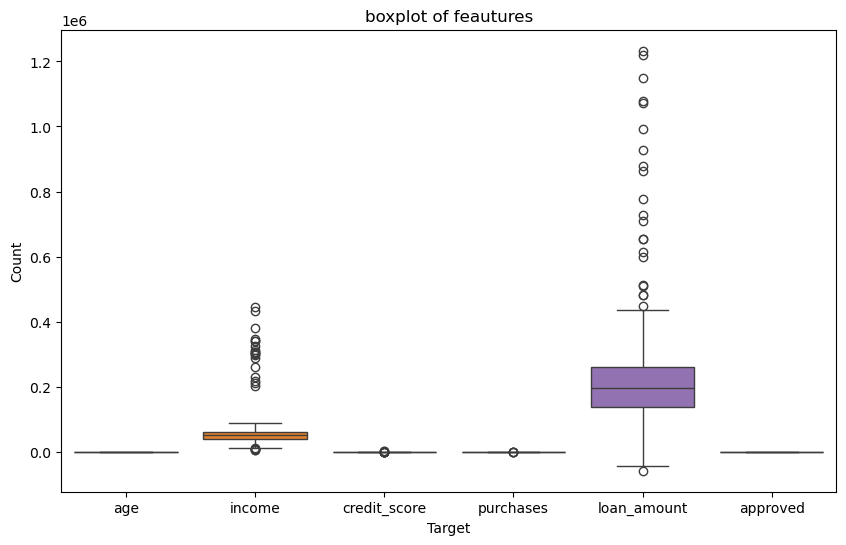

In [48]:
#step 4=data visulaization
plt.figure(figsize=(10, 6))
sns.boxplot(data=df)
plt.title('boxplot of feautures')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()


In [49]:
# handled the missing values
#find the income column which have missing values
income_median = round(df['income'].median(), 2)
credit_score_median = round(df['credit_score'].median(), 2)
loan_amount_median = round(df['loan_amount'].median(), 2)

#fill the missing values with median values
df['income'].fillna(income_median, inplace=True)
df['credit_score'].fillna(credit_score_mean, inplace=True)
df['loan_amount'].fillna(loan_amount_median, inplace=True)

C:\Users\ntt\AppData\Local\Temp\ipykernel_22036\1168012493.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['income'].fillna(income_median, inplace=True)
C:\Users\ntt\AppData\Local\Temp\ipykernel_22036\1168012493.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example

In [50]:
#  handle the outliers using IQR method

outlier_columns = ['income', 'credit_score', 'loan_amount']

for col in outlier_columns:

    # find Quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # find IQR 
    IQR = Q3 - Q1

    # find lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # handled the outliers clipping the values to the lower and upper bounds
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)


In [51]:
# drop  the city column because it is not useful for our analysis
df.drop('city', axis=1, inplace=True)


In [52]:
df['gender'].value_counts()

gender
Female    540
Male      510
Name: count, dtype: int64

In [53]:
#replace the gender columns values with 0 and 1
df['gender'] = df['gender'].replace({'Male': 0, 'Female': 1})
df['gender'] = df['gender'].replace({'male': 0, 'female': 1})

C:\Users\ntt\AppData\Local\Temp\ipykernel_22036\4024615416.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['gender'] = df['gender'].replace({'Male': 0, 'Female': 1})


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           1050 non-null   int64  
 1   income        1050 non-null   float64
 2   credit_score  1050 non-null   float64
 3   gender        1050 non-null   int64  
 4   purchases     1050 non-null   int64  
 5   loan_amount   1050 non-null   float64
 6   approved      1050 non-null   int64  
dtypes: float64(3), int64(4)
memory usage: 57.6 KB


In [61]:
# handled the imbalanced dataset using RandomOverSampler technique

# 1: RadomOverSampler technique
from imblearn.over_sampling import RandomOverSampler

# instane of RandomOverSampler
ros = RandomOverSampler(random_state=42)

# fit and transform the training data
X_resampled, y_resampled = ros.fit_resample(x, y)

In [62]:
# 2: SMOTE technique
from imblearn.over_sampling import SMOTE

# instance of SMOTE
smote = SMOTE(random_state=42)

# fit and transform the training data
x_resampled, y_resampled = smote.fit_resample(x, y)


In [55]:
# step=5= aplit the dataset into features and target variable
x=df.drop('approved', axis=1)
y=df['approved']


In [63]:
# Step 6: Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_resampled, y_resampled, test_size=0.2, random_state=42)

In [64]:
#step 7 = handle the imbalanced dataset using RandomOverSampler technique
from sklearn.linear_model import LogisticRegression

#instance of LogisticRegression
LR = LogisticRegression()

# train the model on x_train and y_train
model = LR.fit(x_train, y_train)

# Predict the target variable on x_test
y_pred = model.predict(x_test)

c:\Users\ntt\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
y_resampled.value_counts()

approved
0    731
1    731
Name: count, dtype: int64

In [66]:
#2:SMOTE  technique
from imblearn.over_sampling import SMOTE
#instance of SMOTE
smote = SMOTE(random_state=42)


In [67]:
#step 7= model buidling
from sklearn.linear_model import LogisticRegression

#instance of LogisticRegression
LR = LogisticRegression()

#train the model on x_train amd y_train
model = LR.fit(x_train, y_train)

#predict the target variable on x_test
y_pred = model.predict(x_test)

c:\Users\ntt\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [68]:
#step 8: model evaluation
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#find the accouracy

accouracy = accuracy_score(y_test, y_pred)

#find the confusion matrix
confusion = confusion_matrix(y_test, y_pred)

#find the classification report
report = classification_report(y_test, y_pred)

In [69]:
print("Accouracy: ", accouracy)
print("Confusion Matrix: \n", confusion)

Accouracy:  0.7030716723549488
Confusion Matrix: 
 [[105  56]
 [ 31 101]]


In [70]:
#report the classification report
report = classification_report(y_test, y_pred)

print(report)


              precision    recall  f1-score   support

           0       0.77      0.65      0.71       161
           1       0.64      0.77      0.70       132

    accuracy                           0.70       293
   macro avg       0.71      0.71      0.70       293
weighted avg       0.71      0.70      0.70       293

